# Symulator

## 1. Konfiguracja

In [63]:
BUNDLE_DIR = "bundle_colab"
ZESTAW_OUT = "dane/symulacja"
IR_LEN = 4096
NOISE_DB = 60.0
SEED = 42
ELEWACJA = 0.0

# SOFA = None
SOFA = "P0001_FreeFieldComp_48kHz.sofa"

OUT_WAV = f"{ZESTAW_OUT}/nagranie.wav"

{"bundle": BUNDLE_DIR, "snr_db": NOISE_DB, "sofa": SOFA or "syntetyczne IR"}

{'bundle': 'bundle_colab',
 'snr_db': 60.0,
 'sofa': 'P0001_FreeFieldComp_48kHz.sofa'}

In [64]:
import json
import os
import numpy as np
import pandas as pd
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import fftconvolve
import decode_bundle


## 2. Wczytanie bundla

In [65]:
with open(os.path.join(BUNDLE_DIR, "manifest.json"), encoding="utf-8") as fh:
    meta = json.load(fh)

data, fs = sf.read(os.path.join(BUNDLE_DIR, "bundle.wav"), always_2d=True)
data = np.asarray(data, dtype=np.float64)
N_SPK = meta["speakers"]
FS = meta["fs"]

{"kanalow": data.shape[1], "probek": data.shape[0], "s": round(data.shape[0] / FS, 1)}

{'kanalow': 2, 'probek': 6210426, 's': 129.4}

## 3. Odpowiedzi impulsowe

In [66]:
def make_ir(fs, ir_len, delay_ms, decay_ms, seed):
    rng = np.random.default_rng(seed)
    ir = np.zeros(ir_len)
    d = int(delay_ms / 1000.0 * fs)
    if 0 <= d < ir_len:
        ir[d] = 1.0
    tau = max(decay_ms / 1000.0 * fs, 1.0)
    ir += rng.standard_normal(ir_len) * 0.15 * np.exp(-np.arange(ir_len) / tau)
    return ir


if SOFA:
    import h5py

    with h5py.File(SOFA, "r") as fh:
        IR_SOFA = np.array(fh["Data.IR"])
        POZ = np.array(fh["SourcePosition"])
        fs_sofa = float(np.array(fh["Data.SamplingRate"]).ravel()[0])
    if int(fs_sofa) != int(FS):
        raise RuntimeError(f"SOFA ma fs={fs_sofa}, bundle {FS} — brak resamplingu")

    poziome = np.where(np.abs(POZ[:, 1] - ELEWACJA) < 1e-6)[0]
    cele = np.linspace(0.0, 360.0, N_SPK, endpoint=False)
    pozycje = np.array([poziome[np.argmin(np.abs(((POZ[poziome, 0] - a + 180) % 360) - 180))]
                        for a in cele])
    true_irs = [IR_SOFA[i, 0, :].astype(float) for i in pozycje]
    opis = pd.DataFrame([{"spk": j + 1, "azymut": POZ[i, 0], "elewacja": POZ[i, 1],
                          "odleglosc_m": POZ[i, 2], "probek": true_irs[j].size}
                         for j, i in enumerate(pozycje)])
    zrodlo_ir = os.path.basename(SOFA)
    etykiety_ir = [f"azymut {POZ[i, 0]:.0f}°, elewacja {POZ[i, 1]:.0f}°"
                   for i in pozycje]
else:
    parametry = [{"spk": j + 1, "delay_ms": 2.0 + j * 1.5, "decay_ms": 80.0 + j * 20.0}
                 for j in range(N_SPK)]
    true_irs = [make_ir(FS, IR_LEN, p["delay_ms"], p["decay_ms"], SEED + p["spk"])
                for p in parametry]
    opis = pd.DataFrame(parametry)
    zrodlo_ir = "syntetyczne"
    etykiety_ir = [f"delay {p['delay_ms']} ms, decay {p['decay_ms']} ms" for p in parametry]

IR_MAX = max(ir.size for ir in true_irs)
opis

,spk,azymut,elewacja,odleglosc_m,probek
0,1,0.0,0.0,1.5,256
1,2,180.0,0.0,1.5,256


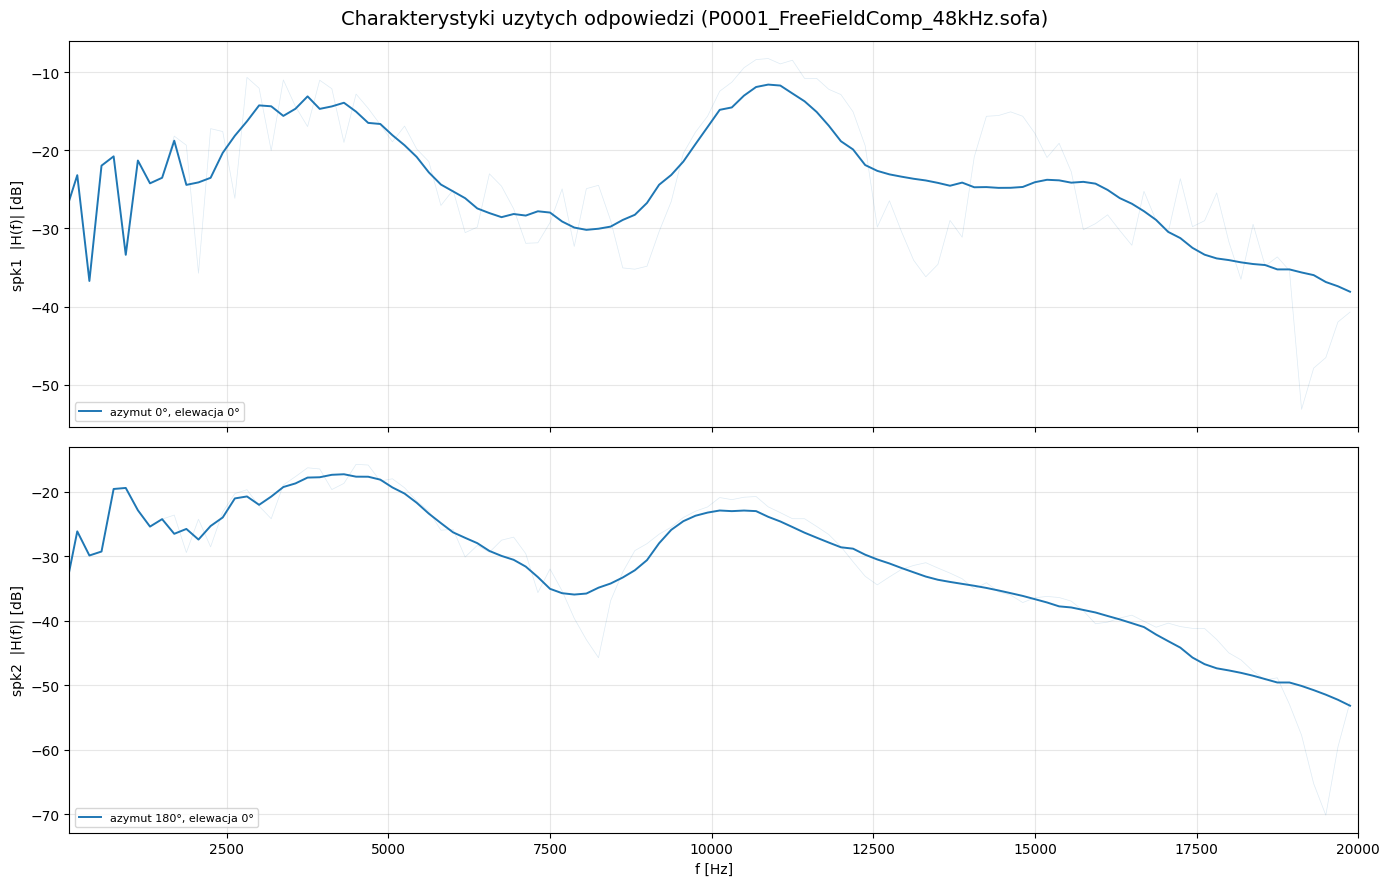

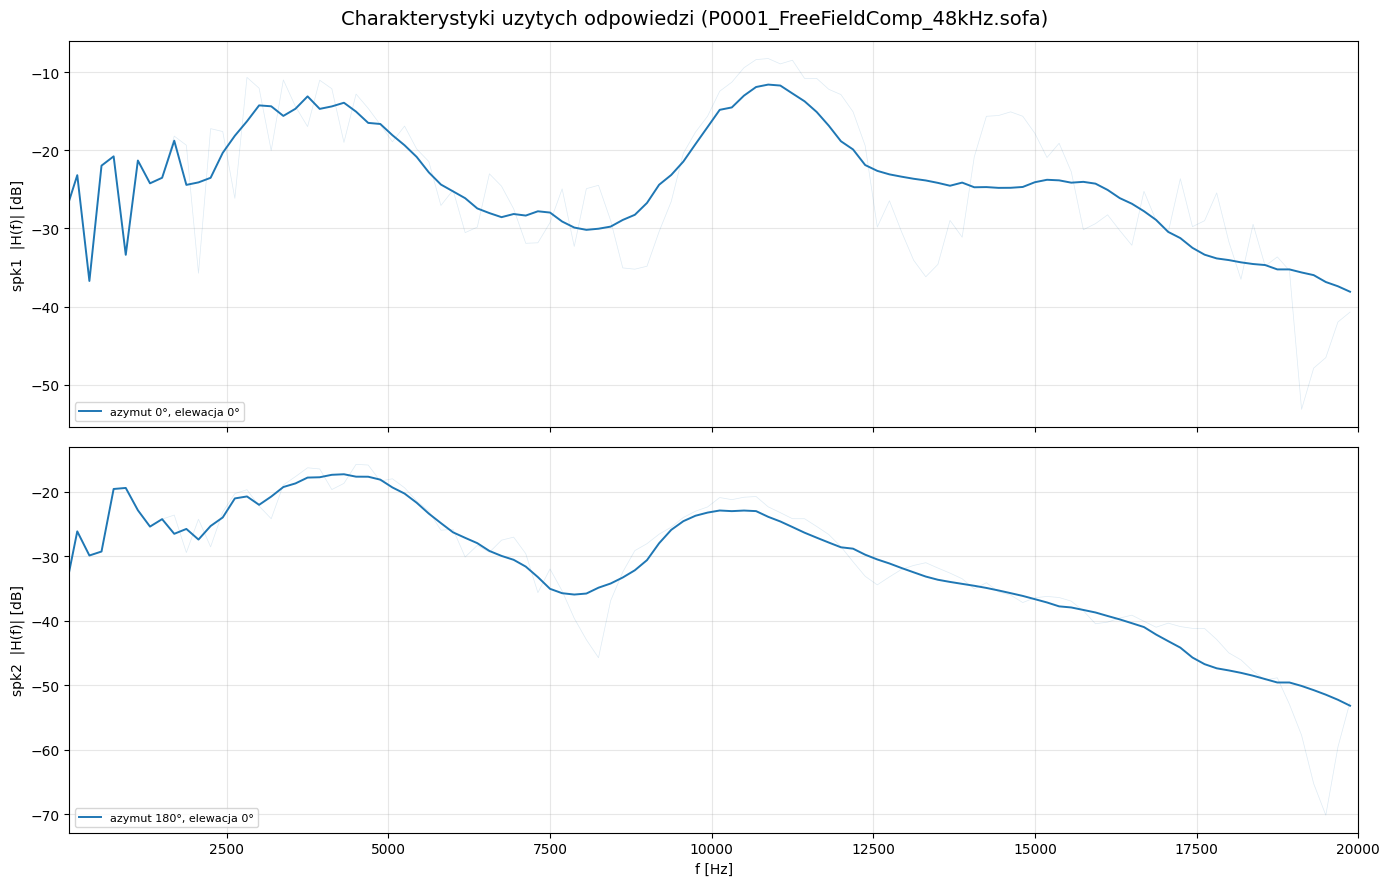

In [67]:
fig, axes = plt.subplots(N_SPK, 1, figsize=(14, 3 + 3 * N_SPK),
                         squeeze=False, sharex=True)
fig.suptitle(f"Charakterystyki uzytych odpowiedzi ({zrodlo_ir})", fontsize=14)

for j in range(N_SPK):
    ax = axes[j][0]
    f, mag_db, mag_sm = decode_bundle._fft_curve(true_irs[j], FS)
    ax.plot(f, mag_db, color="#1f77b4", alpha=0.15, lw=0.5)
    ax.plot(f, mag_sm, color="#1f77b4", lw=1.4, label=etykiety_ir[j])
    ax.set_ylabel(f"spk{j+1}  |H(f)| [dB]")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="lower left")

axes[-1][0].set_xlabel("f [Hz]")
axes[-1][0].set_xlim(decode_bundle.FMIN_PLOT_HZ, decode_bundle.FMAX_HZ)
fig.tight_layout()
fig


## 4. Splot

In [68]:
y = np.zeros(data.shape[0] + IR_MAX - 1)
for j in range(N_SPK):
    conv = fftconvolve(data[:, j], true_irs[j])
    y[:conv.size] += conv

rng = np.random.default_rng(SEED + 999)
sig_p = max(float(np.mean(y**2)), 1e-30)
noise_p = sig_p / (10 ** (NOISE_DB / 10))
y_noisy = y + rng.standard_normal(y.size) * np.sqrt(noise_p)

zmierzony = 20 * np.log10(float(np.sqrt(np.mean(y**2)))
                          / max(float(np.sqrt(np.mean((y_noisy - y)**2))), 1e-30))
{"snr_zadany": NOISE_DB, "snr_zmierzony": round(zmierzony, 2)}

{'snr_zadany': 60.0, 'snr_zmierzony': np.float64(60.0)}

## 5. Zapis

In [69]:
import shutil

os.makedirs(ZESTAW_OUT, exist_ok=True)
x = y_noisy / max(float(np.max(np.abs(y_noisy))), 1e-30) * 0.95
sf.write(OUT_WAV, x.astype(np.float32), FS, subtype="FLOAT")
shutil.copy(os.path.join(BUNDLE_DIR, "manifest.json"),
            os.path.join(ZESTAW_OUT, "manifest.json"))

ir_dir = os.path.join(ZESTAW_OUT, "true_irs")
os.makedirs(ir_dir, exist_ok=True)
for j, ir in enumerate(true_irs):
    np.save(os.path.join(ir_dir, f"true_h{j+1}.npy"), ir)

sorted(os.listdir(ZESTAW_OUT))

['manifest.json', 'nagranie.wav', 'true_irs']

## 6. Walidacja

In [70]:
fs_rec, y_rec = decode_bundle.read_wav_mono(OUT_WAV)

odtworzone = {}
for method in decode_bundle.METHODS:
    if method.key == "mls_reciprocal" and \
            not any(s["name"] == "mls_reciprocal_pair" for s in meta["segments"]):
        continue
    odtworzone[method.key] = method.decode(y_rec, json.loads(json.dumps(meta)), IR_LEN)

sorted(odtworzone)

['golay_hadamard',
 'gold',
 'mls_hadamard',
 'mls_reciprocal',
 'solo_golay',
 'solo_mls']

In [71]:
def dopasuj(est, ref):
    n = min(est.size, ref.size)
    e, r = est[:n], ref[:n]
    skala = float(np.dot(e, r)) / max(float(np.dot(e, e)), 1e-30)
    blad = e * skala - r
    return {"korelacja": float(np.dot(e, r) /
                               max(np.sqrt(np.dot(e, e) * np.dot(r, r)), 1e-30)),
            "nmse_db": 10 * np.log10(max(float(np.mean(blad**2)), 1e-30)
                                     / max(float(np.mean(r**2)), 1e-30))}


pd.DataFrame([{"metoda": k, "spk": j + 1, **dopasuj(irs[j], true_irs[j])}
              for k, irs in odtworzone.items() for j in range(N_SPK)]).round(4)

,metoda,spk,korelacja,nmse_db
0,solo_golay,1,1.0000,-95.2625
1,solo_golay,2,1.0000,-89.1232
2,golay_hadamard,1,1.0000,-98.5926
3,golay_hadamard,2,1.0000,-91.6464
4,solo_mls,1,1.0000,-56.3940
5,solo_mls,2,1.0000,-54.5761
6,mls_hadamard,1,1.0000,-56.4168
7,mls_hadamard,2,1.0000,-54.5675
8,mls_reciprocal,1,0.9998,-34.3510
9,mls_reciprocal,2,0.9969,-22.0621
